In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import torch
from torch import nn
from pathlib import Path

In [2]:
out_path = Path.cwd().parent / "data/processed"
device = "cuda" if torch.cuda.is_available() else "cpu"

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "lines.linewidth": 1.6, "legend.frameon": False,
})

In [3]:
surf = pd.read_pickle(out_path / "surface_clean.pkl")  # see 04_surface_eda; bad prints are NaN
TENORS = list(surf.columns.get_level_values("tenor").unique())
MONEYNESS = list(surf.columns.get_level_values("moneyness").unique())
n_tenors, n_moneyness = len(TENORS), len(MONEYNESS)

TEST_START = "2021-01-01"
test = surf.index[surf.index >= TEST_START]
months = list(pd.Series(test, index=test).groupby(test.to_period("M")))
y = surf.loc[test]
pred_rw = surf.shift(1).loc[test]

# inputs: forward-fill only uses the past, so it does not leak; targets keep the NaN
surf_in = surf.ffill()
target = surf.diff().shift(-1)

In [4]:
def fit_ar1(s, end, window=252):
    df = pd.concat([s, s.shift(1)], axis=1, keys=["y", "x"]).dropna()
    df = df[df.index < end].iloc[-window:]
    return sm.RLM(df["y"], sm.add_constant(df["x"]), M=sm.robust.norms.HuberT()).fit().params


def predict_ar1():
    """Best linear baseline on the 30-day smile (02_baselines): per-point AR(1) on changes, 252 days, Huber."""
    d = surf.diff()
    pred = pd.DataFrame(index=test, columns=surf.columns, dtype=float)
    for month, days in months:
        for col in surf.columns:
            c, b = fit_ar1(d[col], days.index[0])
            pred.loc[days.index, col] = surf[col].shift(1).loc[days.index] + c + b * d[col].shift(1).loc[days.index]
    return pred


preds = {"persistence": pred_rw, "ar1_rolling252_huber": predict_ar1()}

In [5]:
def make_windows(L):
    """X[t]: last L surfaces up to t, channels (daily change, level); shape (days, 2, L, tenors, moneyness)."""
    level = surf_in.to_numpy().reshape(len(surf), n_tenors, n_moneyness)
    change = surf_in.diff().to_numpy().reshape(len(surf), n_tenors, n_moneyness)
    X = np.full((len(surf), 2, L, n_tenors, n_moneyness), np.nan, dtype=np.float32)
    for i in range(L, len(surf)):
        X[i, 0] = change[i - L + 1 : i + 1]
        X[i, 1] = level[i - L + 1 : i + 1]
    return X

In [6]:
class SurfaceCNN(nn.Module):
    """3D convolutions over (time, tenor, moneyness), average over time, then a head to the 63 changes.

    head="conv": a 1x1 convolution, the same weights at every grid point (few parameters).
    head="dense": a linear layer from the whole feature map, a separate set of weights per point.
    """

    def __init__(self, channels=16, head="conv"):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv3d(2, channels, 3, padding=1), nn.GELU(),
            nn.Conv3d(channels, channels, 3, padding=1), nn.GELU(),
        )
        self.head_type = head
        if head == "conv":
            self.head = nn.Conv2d(channels, 1, 1)
        else:
            self.head = nn.Linear(channels * n_tenors * n_moneyness, n_tenors * n_moneyness)
        # zero output at init: the untrained network is persistence
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x):
        h = self.conv(x).mean(dim=2)
        return self.head(h).flatten(1) if self.head_type == "conv" else self.head(h.flatten(1))

In [7]:
def fit_cnn(X, Y, seed, head, val_frac=0.15, epochs=300, patience=30, batch=64):
    """Huber loss, AdamW, early stopping on the last val_frac of the training window."""
    torch.manual_seed(seed)
    n_val = max(int(val_frac * len(X)), 20)
    Xt, Yt, Xv, Yv = X[:-n_val], Y[:-n_val], X[-n_val:], Y[-n_val:]
    model = SurfaceCNN(head=head).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.HuberLoss(delta=1.0)
    best, best_state, wait = np.inf, None, 0
    for epoch in range(epochs):
        model.train()
        for b in torch.randperm(len(Xt)).split(batch):
            opt.zero_grad()
            loss_fn(model(Xt[b]), Yt[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(Xv), Yv).item()
        if val < best:
            best, best_state, wait = val, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, epoch

In [8]:
def predict_cnn(L=5, head="conv", seeds=5):
    """Walk-forward, expanding window, refit on the first day of each month; average of `seeds` networks."""
    X, Y = make_windows(L), target.to_numpy(dtype=np.float32)
    ok = np.isfinite(X).all(axis=(1, 2, 3, 4)) & np.isfinite(Y).all(axis=1)
    pred = pd.DataFrame(index=test, columns=surf.columns, dtype=float)
    epochs = []
    for month, days in months:
        start = days.index[0]
        train = ok & (surf.index < start)
        train[:-1] &= surf.index[1:] < start  # the target day t+1 must also be before the refit date
        Xtr, Ytr = X[train], Y[train]

        # scaling fitted on the training window only; each target point by its own std
        # (short tenors move about four times more than long ones, see 04_surface_eda)
        sd_change, mu_level, sd_level, sd_y = Xtr[:, 0].std(), Xtr[:, 1].mean(), Xtr[:, 1].std(), Ytr.std(axis=0)
        def scale(x):
            x = x.copy()
            x[:, 0] /= sd_change
            x[:, 1] = (x[:, 1] - mu_level) / sd_level
            return torch.tensor(x, device=device)

        Xte = scale(X[surf.index.get_indexer(days.index) - 1])  # forecast for t uses the window ending at t-1
        out = []
        for seed in range(seeds):
            model, ep = fit_cnn(scale(Xtr), torch.tensor(Ytr / sd_y, device=device), seed, head)
            epochs.append(ep)
            with torch.no_grad():
                out.append(model(Xte).cpu().numpy() * sd_y)
        pred.loc[days.index] = pred_rw.loc[days.index].to_numpy() + np.mean(out, axis=0)
    return pred, np.array(epochs)

In [9]:
cnn_epochs = {}
for name, kw in {
    "cnn_conv_head": {"head": "conv"},
    "cnn_dense_head": {"head": "dense"},
}.items():
    preds[name], cnn_epochs[name] = predict_cnn(**kw)

pd.DataFrame({k: pd.Series(v).describe() for k, v in cnn_epochs.items()}).loc[["mean", "min", "max"]].round(0)

,cnn_conv_head,cnn_dense_head
mean,48.0,43.0
min,31.0,30.0
max,163.0,140.0


In [10]:
valid = y.notna().all(axis=1)
for p in preds.values():
    valid &= p.notna().all(axis=1)

errors = {name: (y - p)[valid] for name, p in preds.items()}
print(f"Evaluated days: {valid.sum()} ({y.index[valid][0]:%Y-%m-%d} to {y.index[valid][-1]:%Y-%m-%d})")

Evaluated days: 1444 (2021-01-04 to 2026-10-07)


In [11]:
def r2_oos(e, e_ref):
    return 1 - (e**2).to_numpy().sum() / (e_ref**2).to_numpy().sum()

summary = pd.DataFrame({
    name: {
        "mae": e.abs().to_numpy().mean(),
        "rmse": np.sqrt((e**2).to_numpy().mean()),
        "mae_vs_rw": e.abs().to_numpy().mean() / errors["persistence"].abs().to_numpy().mean() - 1,
        "r2_oos_vs_rw": r2_oos(e, errors["persistence"]),
    }
    for name, e in errors.items()
}).T
summary.round(4)

,mae,rmse,mae_vs_rw,r2_oos_vs_rw
persistence,0.4597,0.8277,0.0000,0.0000
ar1_rolling252_huber,0.4571,0.8218,-0.0057,0.0143
cnn_conv_head,0.4546,0.8241,-0.0112,0.0089
cnn_dense_head,0.4546,0.8231,-0.0112,0.0111


In [12]:
mae_by_tenor = pd.DataFrame({
    name: e.abs().T.groupby(level="tenor", sort=False).mean().T.mean() for name, e in errors.items()
}).T
rel_by_tenor = mae_by_tenor.div(mae_by_tenor.loc["persistence"]) - 1
pd.concat({"mae": mae_by_tenor, "mae_vs_rw": rel_by_tenor}).round(3)

tenor                           30DAY  60DAY   3MTH   6MTH  12MTH  18MTH  \
mae       persistence           0.907  0.622  0.535  0.402  0.297  0.240   
          ar1_rolling252_huber  0.899  0.619  0.532  0.402  0.296  0.239   
          cnn_conv_head         0.892  0.614  0.529  0.399  0.294  0.239   
          cnn_dense_head        0.893  0.614  0.529  0.399  0.294  0.239   
mae_vs_rw persistence           0.000  0.000  0.000  0.000  0.000  0.000   
          ar1_rolling252_huber -0.009 -0.005 -0.004 -0.002 -0.003 -0.005   
          cnn_conv_head        -0.017 -0.013 -0.010 -0.008 -0.008 -0.006   
          cnn_dense_head       -0.016 -0.012 -0.011 -0.008 -0.008 -0.007   

tenor                           24MTH  
mae       persistence           0.215  
          ar1_rolling252_huber  0.213  
          cnn_conv_head         0.214  
          cnn_dense_head        0.214  
mae_vs_rw persistence           0.000  
          ar1_rolling252_huber -0.008  
          cnn_conv_head        -0.004  
          cnn_dense_head       -0.005

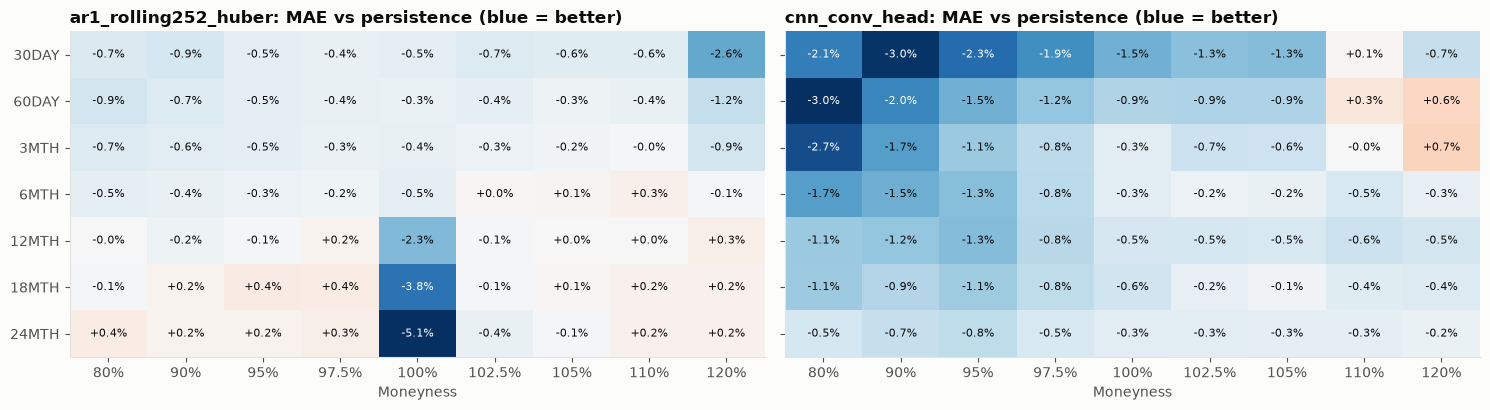

In [13]:
def plot_grid(ax, grid, title, fmt="{:+.1%}"):
    vmax = np.abs(grid.to_numpy()).max()
    ax.imshow(grid, cmap="RdBu_r", aspect="auto", vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(grid.shape[1]), [f"{m:g}%" for m in grid.columns])
    ax.set_yticks(range(grid.shape[0]), grid.index)
    ax.set_xlabel("Moneyness")
    ax.grid(False)
    ax.set_title(title)
    for (i, j), v in np.ndenumerate(grid.to_numpy()):
        ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 * vmax else INK)


mae_points = pd.DataFrame({name: e.abs().mean() for name, e in errors.items()})
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, name in zip(axes, ["ar1_rolling252_huber", "cnn_conv_head"]):
    grid = (mae_points[name] / mae_points["persistence"] - 1).unstack().loc[TENORS]
    plot_grid(ax, grid, f"{name}: MAE vs persistence (blue = better)")
plt.tight_layout()
plt.show()

In [14]:
def diebold_mariano(e_ref, e, loss, maxlags=5):
    dl = loss(e_ref).mean(axis=1) - loss(e).mean(axis=1)
    res = sm.OLS(dl.to_numpy(), np.ones(len(dl))).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return res.tvalues[0], res.pvalues[0]

losses = {"squared": lambda e: e**2, "absolute": lambda e: e.abs()}
dm = pd.DataFrame({
    (ref, name, loss_name): dict(zip(["t_stat", "p_value"], diebold_mariano(errors[ref], errors[name], loss)))
    for ref in ["persistence", "ar1_rolling252_huber"]
    for name in ["ar1_rolling252_huber", "cnn_conv_head", "cnn_dense_head"]
    if name != ref
    for loss_name, loss in losses.items()
}).T
dm.round(3)

t_stat  p_value
persistence          ar1_rolling252_huber squared    1.217    0.224
                                          absolute   1.241    0.215
                     cnn_conv_head        squared    0.500    0.617
                                          absolute   1.894    0.058
                     cnn_dense_head       squared    0.534    0.594
                                          absolute   1.626    0.104
ar1_rolling252_huber cnn_conv_head        squared   -0.338    0.735
                                          absolute   1.014    0.311
                     cnn_dense_head       squared   -0.174    0.862
                                          absolute   0.840    0.401

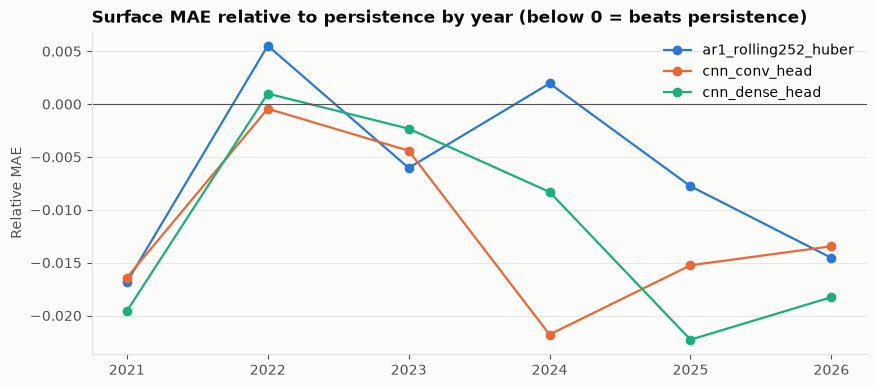

In [15]:
mae_by_year = pd.DataFrame({name: e.abs().mean(axis=1).groupby(e.index.year).mean() for name, e in errors.items()})
rel = mae_by_year.drop(columns="persistence").div(mae_by_year["persistence"], axis=0) - 1

fig, ax = plt.subplots(figsize=(10, 4.2))
for name, color in zip(rel.columns, COLORS):
    ax.plot(rel.index, rel[name], marker="o", color=color, label=name)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_title("Surface MAE relative to persistence by year (below 0 = beats persistence)")
ax.set_ylabel("Relative MAE")
ax.legend()
plt.show()

In [16]:
pd.to_pickle(preds, out_path / "surface_preds.pkl")